## Exploratory Data Analysis (EDA)

We will investigate:
1. Which product category generates the highest revenue?
2. Which state generates the most sales?
3. Which month has the highest sales?
4. Which payment method is most popular?
5. Which products generate the highest profit?
6. What is the relationship between discounts and profitability?
7. Which customer groups purchase the most?

In [2]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

# Set visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Upload cleaned dataset

df = pd.read_csv("retail_sales_cleaned.csv")


In [4]:
# Convert date column

df["order_date"] = pd.to_datetime(df["order_date"])

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:
df.head(10)

,order_line_id,order_date,customer_id,gender,age,city,state,product,category,quantity,...,gross_sales,discount_amount,net_sales,total_cost,profit,profit_margin_pct,year,month,month_name,quarter
0,OL00001,2025-07-30,CUST0616,Female,43,Enugu,Enugu,T-Shirt,Fashion,2,...,33200,3320.0,29880.0,18400,11480.0,38.420348,2025,7,July,Q3
1,OL00002,2024-08-30,CUST0082,Male,29,Port Harcourt,Rivers,Smartphone,Electronics,1,...,200200,20020.0,180180.0,135800,44380.0,24.630925,2024,8,August,Q3
2,OL00003,2025-03-27,CUST0556,Female,24,Yaba,Lagos,Makeup Kit,Beauty,5,...,160500,8025.0,152475.0,69500,82975.0,54.418757,2025,3,March,Q1
3,OL00004,2025-07-01,CUST0240,Male,40,Benin City,Edo,Rice 10Kg,Groceries,1,...,23100,0.0,23100.0,19700,3400.0,14.718615,2025,7,July,Q3
4,OL00005,2024-09-21,CUST0762,Male,42,Ibadan,Oyo,Smartphone,Electronics,2,...,371400,37140.0,334260.0,269000,65260.0,19.523724,2024,9,September,Q3
5,OL00006,2023-05-19,CUST0669,Male,30,Obio-Akpor,Rivers,Handbag,Fashion,1,...,46200,4620.0,41580.0,25500,16080.0,38.672439,2023,5,May,Q2
6,OL00007,2024-06-27,CUST0536,Female,33,Yaba,Lagos,Bedsheet Set,Home & Kitchen,1,...,39400,3940.0,35460.0,20200,15260.0,43.034405,2024,6,June,Q2
7,OL00008,2025-02-05,CUST0885,Female,30,Kaduna,Kaduna,Cooking Oil 5L,Groceries,1,...,18400,1840.0,16560.0,13400,3160.0,19.082126,2025,2,February,Q1
8,OL00009,2023-12-05,CUST0753,Male,22,Kano,Kano,Laptop,Electronics,3,...,1984500,99225.0,1885275.0,1482900,402375.0,21.343040,2023,12,December,Q4
9,OL00010,2024-05-04,CUST0417,Female,18,Maitama,Abuja,Smartphone,Electronics,2,...,346800,17340.0,329460.0,282400,47060.0,14.283980,2024,5,May,Q2


In [11]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.info()

Rows: 5000
Columns: 27
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 27 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   order_line_id      5000 non-null   object        
 1   order_date         5000 non-null   datetime64[ns]
 2   customer_id        5000 non-null   object        
 3   gender             5000 non-null   object        
 4   age                5000 non-null   int64         
 5   city               5000 non-null   object        
 6   state              5000 non-null   object        
 7   product            5000 non-null   object        
 8   category           5000 non-null   object        
 9   quantity           5000 non-null   int64         
 10  unit_price_ngn     5000 non-null   int64         
 11  unit_cost_ngn      5000 non-null   int64         
 12  discount_pct       5000 non-null   float64       
 13  payment_method     5000 non-null   objec

## Key Performance Indicator (KPIs)

1. Total revenue.

2. Total profit.

3. Total quantity sold.

4. Number of customers.

5. Average transaction line sales.

6. Average profit margin.

In [14]:
# Calculate business KPIs

total_revenue = df["net_sales"].sum()

total_profit = df["profit"].sum()

total_quantity = df["quantity"].sum()

total_customers = df["customer_id"].nunique()

total_transactions = df["order_line_id"].nunique()

average_sales_per_line = df["net_sales"].mean()

overall_profit_margin = (total_profit / total_revenue
) * 100

print("RETAIL SALES BUSINESS KPIs")
print("--------------------------")

print(f"Total Revenue: ₦{total_revenue:,.2f}")
print(f"Total Profit: ₦{total_profit:,.2f}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Order Lines: {total_transactions:,}")
print(f"Average Sales per Line: ₦{average_sales_per_line:,.2f}")
print(f"Profit Margin: {overall_profit_margin:.2f}%")

RETAIL SALES BUSINESS KPIs
--------------------------
Total Revenue: ₦787,438,680.00
Total Profit: ₦213,093,880.00
Total Quantity Sold: 10,039
Total Customers: 1,184
Order Lines: 5,000
Average Sales per Line: ₦157,487.74
Profit Margin: 27.06%


## Analyse sales by product category
Which product categories generate the most revenue.

In [18]:
# Revenue by product category

category_sales = (df.groupby("category")["net_sales"].sum()
.sort_values(ascending=False))

print(category_sales)

category
Electronics       513501235.0
Home & Kitchen    103100485.0
Fashion            81848755.0
Beauty             62287435.0
Groceries          26700770.0
Name: net_sales, dtype: float64


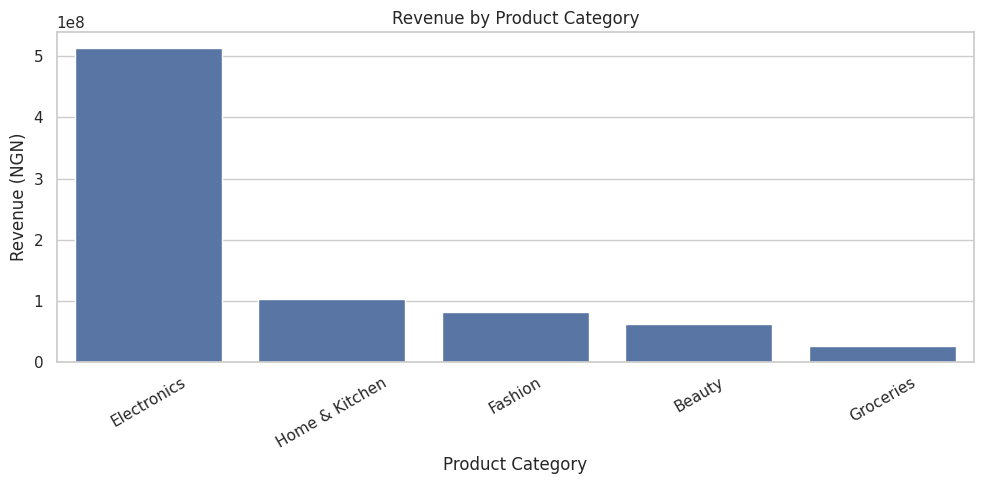

In [19]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=category_sales.index,
    y=category_sales.values
)

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue (NGN)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

## Identify the best selling products
Which products have the highest sales volume?

In [24]:
# Total quantity sold by product

top_products = (df.groupby("product")["quantity"].sum()
.sort_values(ascending=False)
.head(10))

print(top_products)

product
Laptop           632
Jeans            623
Smartphone       593
Headphones       566
Handbag          543
T-Shirt          539
Power Bank       538
Sneakers         523
Beverage Pack    517
Blender          511
Name: quantity, dtype: int64


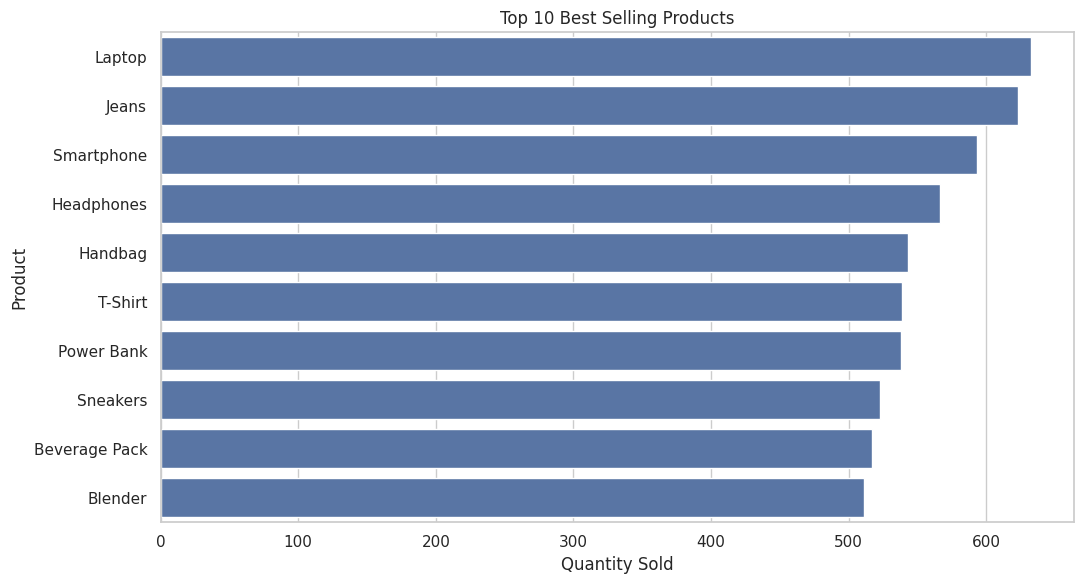

In [25]:
plt.figure(figsize=(11, 6))

sns.barplot(
    x=top_products.values,
    y=top_products.index
)

plt.title("Top 10 Best Selling Products")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

## Analyse monthly revenue trends
Which months generate the highest revenue?

In [26]:
# Group revenue by month

monthly_sales = (df.groupby("month_name")["net_sales"].sum())

# Put months in calendar order

month_order = [
    "January", "February", "March",
    "April", "May", "June",
    "July", "August", "September",
    "October", "November", "December"
]

monthly_sales = monthly_sales.reindex(month_order)

print(monthly_sales)

month_name
January      59856110.0
February     68721675.0
March        73786415.0
April        74431380.0
May          59327160.0
June         54833295.0
July         70487200.0
August       83767395.0
September    62083340.0
October      60484310.0
November     63553855.0
December     56106545.0
Name: net_sales, dtype: float64


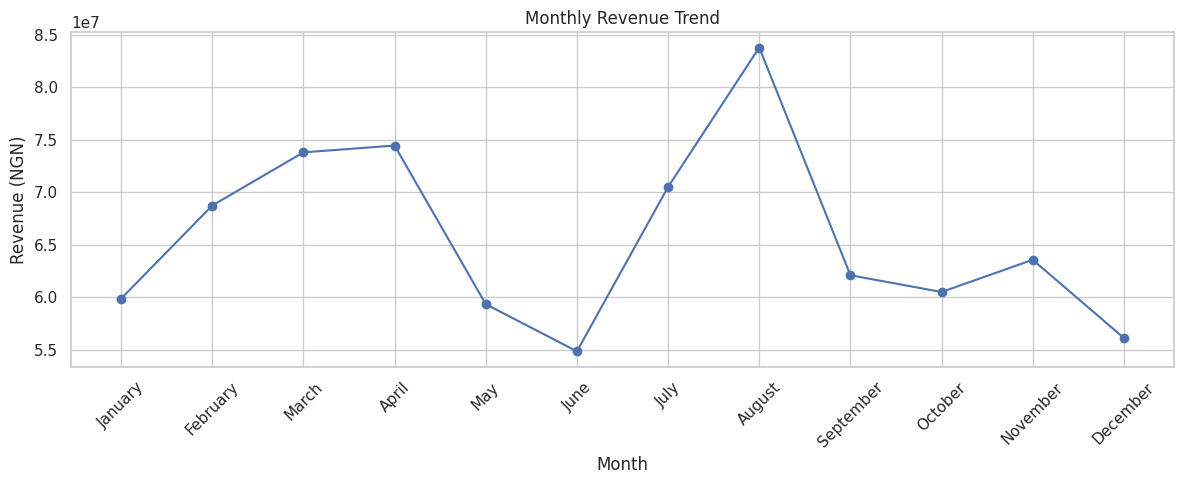

In [27]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (NGN)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Analyse sales by state
Which Nigerian state contributes the most revenue?

In [28]:
# Revenue by state

state_sales = (df.groupby("state")["net_sales"].sum()
    .sort_values(ascending=False))

print(state_sales)

state
Lagos     179384580.0
Abuja     103051980.0
Rivers     94201640.0
Oyo        80840670.0
Kano       66592735.0
Delta      66502400.0
Edo        53232105.0
Ogun       50317060.0
Enugu      47310005.0
Kaduna     46005505.0
Name: net_sales, dtype: float64


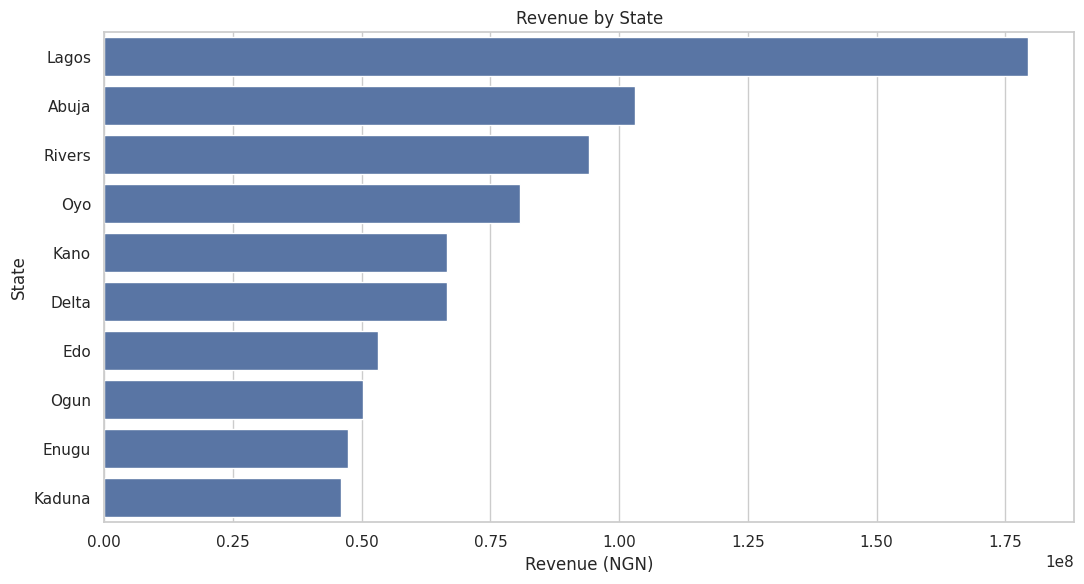

In [29]:
plt.figure(figsize=(11, 6))

sns.barplot(
    x=state_sales.values,
    y=state_sales.index
)

plt.title("Revenue by State")
plt.xlabel("Revenue (NGN)")
plt.ylabel("State")

plt.tight_layout()
plt.show()

## Analyse customer payment methods
Which payment method is most frequently used?

In [30]:
payment_analysis = (df.groupby("payment_method").agg(
        Total_Orders=("order_line_id", "count"),
        Total_Revenue=("net_sales", "sum"))
    .sort_values(
        by="Total_Orders",
        ascending=False))

print(payment_analysis)

                  Total_Orders  Total_Revenue
payment_method                               
Bank Transfer             1510    240754500.0
Card                      1414    230888335.0
Ussd                       898    129611065.0
Cash On Delivery           776    129255960.0
Wallet                     402     56928820.0


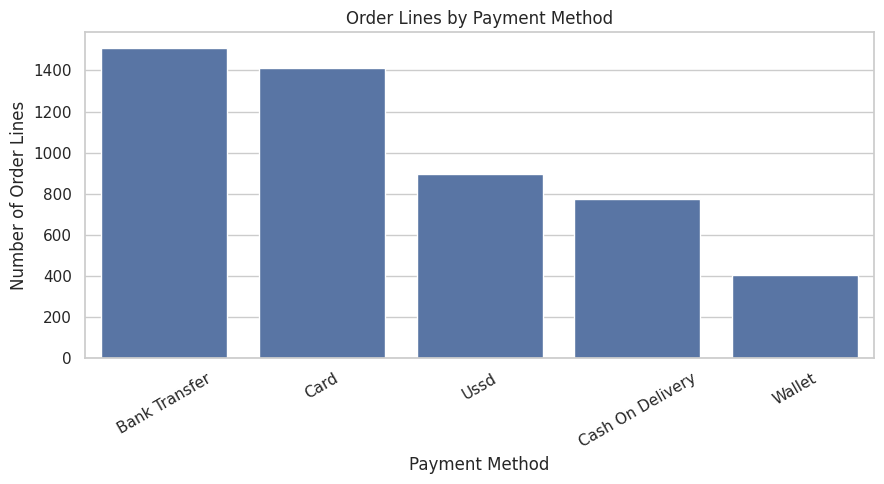

In [31]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=payment_analysis.index,
    y=payment_analysis["Total_Orders"].values
)

plt.title("Order Lines by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Order Lines")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

## Analyse order status
What percentage of order lines are cancelled or returned?

In [32]:
status_analysis = df["order_status"].value_counts()

print(status_analysis)

order_status
Delivered    3916
Shipped       514
Cancelled     330
Returned      240
Name: count, dtype: int64


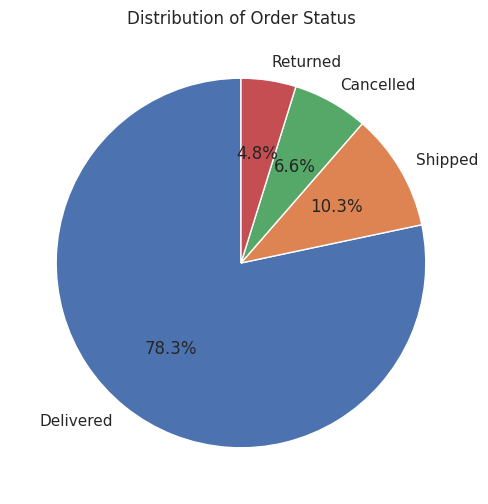

In [33]:
plt.figure(figsize=(8, 6))

plt.pie(
    status_analysis.values,
    labels=status_analysis.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Order Status")

plt.show()

## Investigate discounts and profitability
Are higher discounts associated with lower average profit margins?

In [34]:
discount_analysis = (df.groupby("discount_pct").agg(
        Total_Revenue=("net_sales", "sum"),
        Total_Profit=("profit", "sum"),
        Average_Profit_Margin=("profit_margin_pct", "mean"))
)

print(discount_analysis)

              Total_Revenue  Total_Profit  Average_Profit_Margin
discount_pct                                                    
0.00            304605700.0    95474900.0              39.652698
0.05            211201435.0    57741535.0              36.224727
0.10            147386790.0    36445790.0              32.149845
0.15             89480435.0    18459135.0              30.104083
0.20             34764320.0     4972520.0              23.172973


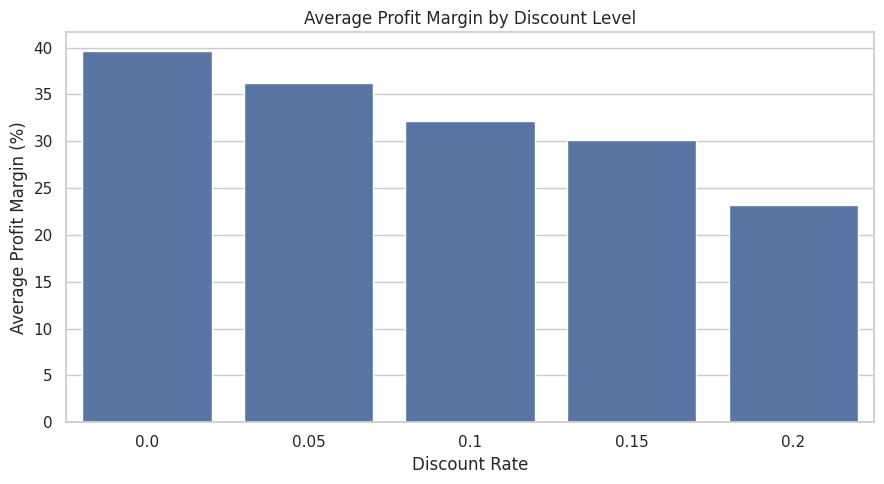

In [35]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=discount_analysis.index,
    y=discount_analysis["Average_Profit_Margin"].values
)

plt.title("Average Profit Margin by Discount Level")
plt.xlabel("Discount Rate")
plt.ylabel("Average Profit Margin (%)")

plt.tight_layout()
plt.show()

## Analyse customer purchasing behaviour
Which 10 customers generate the highest revenue?

In [36]:
customer_analysis = (df.groupby("customer_id").agg(
        Total_Order_Lines=("order_line_id", "count"),
        Total_Quantity=("quantity", "sum"),
        Total_Revenue=("net_sales", "sum"),
        Total_Profit=("profit", "sum"))
    .sort_values(
        by="Total_Revenue",
        ascending=False))

print(customer_analysis.head(10))

             Total_Order_Lines  Total_Quantity  Total_Revenue  Total_Profit
customer_id                                                                
CUST0881                     7              20      5257820.0     1457920.0
CUST0278                     6              19      4744230.0     1040630.0
CUST0921                    11              26      4511465.0     1253965.0
CUST0565                     9              21      4171730.0     1057230.0
CUST0739                     5              10      4063070.0     1013270.0
CUST1152                     5              13      3994945.0      820945.0
CUST0685                     6              13      3842120.0      897920.0
CUST0193                     8              23      3812685.0      435885.0
CUST0015                     9              23      3794770.0      841370.0
CUST0667                     6              16      3700140.0      971240.0


## Compare revenue and profit by category


In [37]:
category_performance = (df.groupby("category").agg(
        Total_Quantity=("quantity", "sum"),
        Total_Revenue=("net_sales", "sum"),
        Total_Cost=("total_cost", "sum"),
        Total_Profit=("profit", "sum"))
    .sort_values(
        by="Total_Profit",
        ascending=False))

print(category_performance)

                Total_Quantity  Total_Revenue  Total_Cost  Total_Profit
category                                                               
Electronics               2329    513501235.0   406421900   107079335.0
Home & Kitchen            1923    103100485.0    66425900    36674585.0
Fashion                   2228     81848755.0    47167900    34680855.0
Beauty                    1583     62287435.0    32723300    29564135.0
Groceries                 1976     26700770.0    21605800     5094970.0


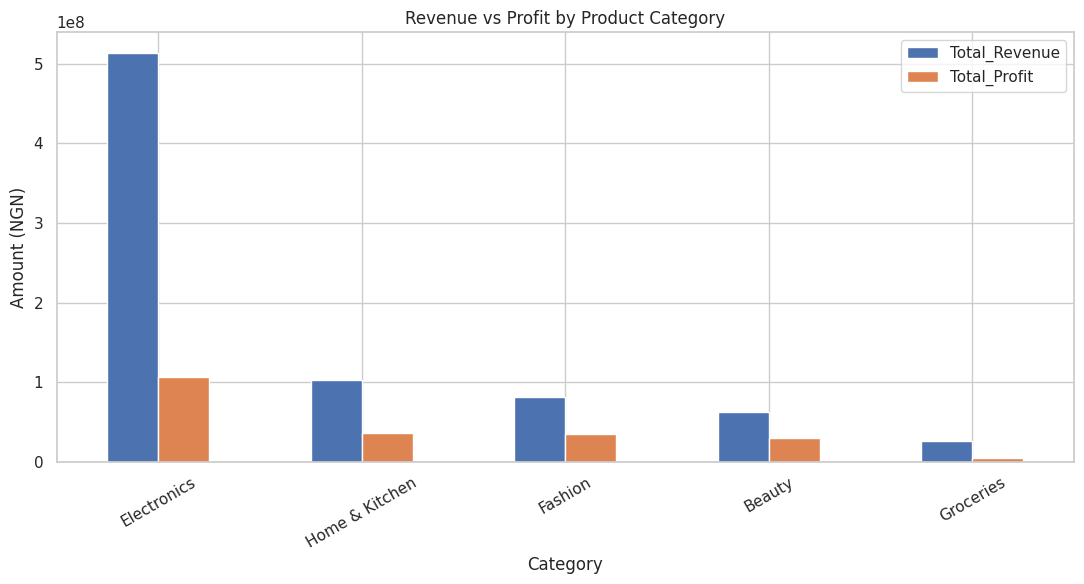

In [38]:
category_performance[
    ["Total_Revenue", "Total_Profit"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Revenue vs Profit by Product Category")
plt.xlabel("Category")
plt.ylabel("Amount (NGN)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Examine revenue by order status


In [39]:
status_revenue = (df.groupby("order_status").agg(
        Order_Lines=("order_line_id", "count"),
        Revenue=("net_sales", "sum"),
        Profit=("profit", "sum")))

print(status_revenue)

              Order_Lines      Revenue       Profit
order_status                                       
Cancelled             330   55034295.0   14378595.0
Delivered            3916  614213640.0  167949240.0
Returned              240   31761860.0    8747660.0
Shipped               514   86428885.0   22018385.0


## EDA Results

In [41]:
# Export analytical summaries

with pd.ExcelWriter("retail_sales_eda_report.xlsx") as writer:

    category_performance.to_excel(
        writer, sheet_name="Category Performance"
    )

    customer_analysis.head(20).to_excel(
        writer, sheet_name="Top Customers"
    )

    payment_analysis.to_excel(
        writer, sheet_name="Payment Analysis"
    )

    status_analysis.to_frame(
        name="Order Lines"
    ).to_excel(
        writer, sheet_name="Order Status"
    )

    state_sales.to_frame(
        name="Revenue"
    ).to_excel(
        writer, sheet_name="State Revenue"
    )

    discount_analysis.to_excel(
        writer, sheet_name="Discount Analysis"
    )

print("EDA report exported successfully!")

EDA report exported successfully!
EDA report exported successfully!


In [42]:
files.download("retail_sales_eda_report.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>